
### Problem
- Mortgage rate rising above 7%
- First-time buyers fell to **21%** of all home buyers, the lowest on record.
- This affects buyers - gen Z, NAR's members, and NAR itself.
- HAI formula

### Data
- Realtor.com home listing
- Income cencus '24
- Mortgage rate @Freddie Mac

### A-P-P-A-S-A Framework
- Ask 
- Prepare
- Process
- Analyze
- Share
- Act



In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### I. ASK:
Can a median-income family afford the median home listing in America's 100 largest metros as of September 2026, and if not, what has to change?
- In each of the top 100 metros, can a median-income family afford the median price listing as of Sep 2026?
- 10% down payment, instead of 20%?
- For the metros that are not affordable with a 10% down payment (Q2), what would have to change to reach break-even (an index of 100)? 

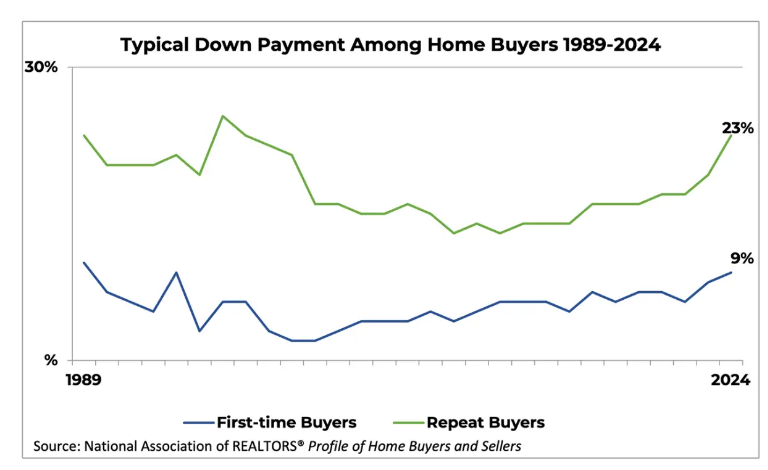
    
    


### II. PREPARE
- Realtor.com metro inventory: Home listing prices by metro, monthly
- Census ACS table B19113 (2024): Median family income by metro
- Freddie Mac 30-year rate (FRED): Mortgage rate, weekly 

### III. PROCESS

In [49]:
DATA = "data/"

# Realtor.com
listings = pd.read_csv(DATA + "RDC_Inventory_Core_Metrics_Metro_History.csv", low_memory=False)

# Census
income = pd.read_csv(DATA + "ACSDT1Y2024.B19113-Data.csv", skiprows=[1])

# Freddie Mac
rates = pd.read_csv(DATA + "MORTGAGE30US.csv", parse_dates=["observation_date"])

print("listings:", listings.shape)
print("income:  ", income.shape)
print("rates:   ", rates.shape)

listings: (113775, 47)
income:   (535, 5)
rates:    (2898, 2)


In [50]:
### Listing df

LATEST_MONTH = 202609   # September 2026
TOP_N = 100             # 100 largest metros by number of households (HouseholdRank)

latest = listings[listings["month_date_yyyymm"] == LATEST_MONTH]
listings_top = latest[latest["HouseholdRank"] <= TOP_N]

print("listings, all rows:    ", len(listings))
print("rows in Sep 2026:      ", len(latest))
print("rows in top 100 metros:", len(listings_top))

listings, all rows:     113775
rows in Sep 2026:       925
rows in top 100 metros: 100


In [51]:
### Income df
income_clean = income.drop(columns="Unnamed: 4").rename(columns={
    "B19113_001E": "median_family_income",      # US dollars per year, 2024
    "B19113_001M": "median_family_income_moe",  # margin of error, US dollars
})
# Metro ID = last 5 digits of GEO_ID
income_clean["cbsa_code"] = income_clean["GEO_ID"].str[-5:].astype(int)
income_clean["income_year"] = 2024

income_clean.head(2)

,GEO_ID,NAME,median_family_income,median_family_income_moe,cbsa_code,income_year
0,310M700US10140,"Aberdeen, WA Micro Area",79824,8499,10140,2024
1,310M700US10180,"Abilene, TX Metro Area",87293,8344,10180,2024


In [52]:
# Rates df
rates["month_date_yyyymm"] = rates["observation_date"].dt.strftime("%Y%m").astype(int)
rates_monthly = rates.groupby("month_date_yyyymm").agg(
    mortgage_rate_pct=("MORTGAGE30US", "mean"),
    n_weeks=("MORTGAGE30US", "count"),
).reset_index()
print(rates_monthly.tail(3))   # the newest month may be partial; check n_weeks


# Each join key must be unique, or the merge would multiply rows and inflate the results
assert len(listings_top) == TOP_N
assert listings_top["cbsa_code"].is_unique
assert income_clean["cbsa_code"].is_unique
assert rates_monthly["month_date_yyyymm"].is_unique

     month_date_yyyymm  mortgage_rate_pct  n_weeks
664             202608             6.6675        4
665             202609             6.8625        4
666             202610             7.3400        2


In [53]:
### Merged all three df

income_cols = ["cbsa_code", "median_family_income", "median_family_income_moe", "income_year"]

merged = (
    listings_top
    .merge(rates_monthly, on="month_date_yyyymm", how="left")
    .merge(income_clean[income_cols], on="cbsa_code", how="left")
)

print("rows before:", len(listings_top))
print("rows after: ", len(merged))
print("metros with no rate:  ", merged["mortgage_rate_pct"].isna().sum())
print("metros with no income:", merged["median_family_income"].isna().sum())

assert len(merged) == len(listings_top)
assert merged["mortgage_rate_pct"].notna().all()
assert merged["median_family_income"].notna().all()

rows before: 100
rows after:  100
metros with no rate:   0
metros with no income: 0


# CLEAN DATA

In [54]:
keep = [
    "month_date_yyyymm",         # month of the listing price and rate
    "cbsa_code",                 # metro ID (the join key)
    "cbsa_title",                # metro name
    "HouseholdRank",             # 1 = largest metro
    "median_listing_price",      # US dollars, asking price (not sale price)
    "mortgage_rate_pct",         # 30-year fixed, percent, monthly average of weekly rates
    "n_weeks",                   # how many weekly rates went into the average
    "median_family_income",      # US dollars per year, 2024
    "median_family_income_moe",  # margin of error, US dollars
    "income_year",               # year the income is from
]

df = (
    merged[keep]
    .rename(columns={"HouseholdRank": "household_rank"})
    .sort_values("household_rank")
    .reset_index(drop=True)
)

# Margin of error as a share of income: how uncertain is each income figure?
df["income_moe_pct"] = df["median_family_income_moe"] / df["median_family_income"]

assert df.notna().all().all()   # no missing values anywhere

print("shape:", df.shape)
print("mortgage rate (%):  ", df["mortgage_rate_pct"].unique(), "from", df["n_weeks"].unique(), "weekly rates")
print("listing price range: ${:,.0f} to ${:,.0f}".format(df["median_listing_price"].min(), df["median_listing_price"].max()))
print("family income range: ${:,.0f} to ${:,.0f}".format(df["median_family_income"].min(), df["median_family_income"].max()))
print("largest income margin of error: {:.1%}".format(df["income_moe_pct"].max()))

df.head(10)

shape: (100, 11)
mortgage rate (%):   [6.8625] from [4] weekly rates
listing price range: $219,675 to $1,388,472
family income range: $60,649 to $190,521
largest income margin of error: 6.9%


,month_date_yyyymm,cbsa_code,cbsa_title,household_rank,median_listing_price,mortgage_rate_pct,n_weeks,median_family_income,median_family_income_moe,income_year,income_moe_pct
0,202609,35620,"New York-Newark-Jersey City, NY-NJ",1,742000.0,6.8625,4,120805,953,2024,0.007889
1,202609,31080,"Los Angeles-Long Beach-Anaheim, CA",2,1034500.0,6.8625,4,109117,1395,2024,0.012784
2,202609,16980,"Chicago-Naperville-Elgin, IL-IN",3,389450.0,6.8625,4,113105,1341,2024,0.011856
3,202609,19100,"Dallas-Fort Worth-Arlington, TX",4,422495.0,6.8625,4,111428,1121,2024,0.010060
4,202609,26420,"Houston-Pasadena-The Woodlands, TX",5,353995.0,6.8625,4,99684,1695,2024,0.017004
5,202609,33100,"Miami-Fort Lauderdale-West Palm Beach, FL",6,490000.0,6.8625,4,92591,1651,2024,0.017831
6,202609,37980,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD",7,374950.0,6.8625,4,116328,1812,2024,0.015577
7,202609,12060,"Atlanta-Sandy Springs-Roswell, GA",8,415000.0,6.8625,4,111073,1311,2024,0.011803
8,202609,47900,"Washington-Arlington-Alexandria, DC-VA-MD-WV",9,572150.0,6.8625,4,155594,2005,2024,0.012886
9,202609,38060,"Phoenix-Mesa-Chandler, AZ",10,475000.0,6.8625,4,106568,1647,2024,0.015455


### IV. ANALYZE
Can a median-income family afford the median home listing in America's 100 largest metros as of September 2026, and if not, what has to change?
- In each of the top 100 metros, can a median-income family afford the median price listing as of Sep 2026?
- In each of the top 100 metros, can a median-income family still afford the median listing with a 10% down payment, the typical first-time buyer's down payment, instead of 20%?
- For the metros that are not affordable with a 10% down payment (Q2), what would have to change to reach break-even (an index of 100)? One change at a time: how far would the listing price have to fall, and how much would family income have to rise? And how many of the 100 metros are affordable at other mortgage rates?

In [55]:
### 1. In each of the top 100 metros, can a median-income family afford the median price listing as of Sep 2026?

# The three inputs for each metro: median listing price, median family income, mortgage rate

df.head(2)




,month_date_yyyymm,cbsa_code,cbsa_title,household_rank,median_listing_price,mortgage_rate_pct,n_weeks,median_family_income,median_family_income_moe,income_year,income_moe_pct
0,202609,35620,"New York-Newark-Jersey City, NY-NJ",1,742000.0,6.8625,4,120805,953,2024,0.007889
1,202609,31080,"Los Angeles-Long Beach-Anaheim, CA",2,1034500.0,6.8625,4,109117,1395,2024,0.012784


In [56]:
# Monthly payment, and the income needed to qualify - NAR's HAI rules

DOWN_PAYMENT = 0.20   
N_PAYMENTS = 360      
MAX_SHARE = 0.25      

q1 = df.copy()

monthly_rate = q1["mortgage_rate_pct"] / 100 / 12

q1["loan_amount"] = q1["median_listing_price"] * (1 - DOWN_PAYMENT)

# Monthly payment: principal and interest ONLY
q1["monthly_payment"] = q1["loan_amount"] * monthly_rate / (1 - (1 + monthly_rate) ** -N_PAYMENTS)

# Yearly income @ 25% of income
q1["qualifying_income"] = q1["monthly_payment"] * 12 / MAX_SHARE

assert len(q1) == TOP_N

q1[["cbsa_title", "median_listing_price", "loan_amount", "monthly_payment", "qualifying_income"]].head(10).round(0)

,cbsa_title,median_listing_price,loan_amount,monthly_payment,qualifying_income
0,"New York-Newark-Jersey City, NY-NJ",742000.0,593600.0,3895.0,186939.0
1,"Los Angeles-Long Beach-Anaheim, CA",1034500.0,827600.0,5430.0,260632.0
2,"Chicago-Naperville-Elgin, IL-IN",389450.0,311560.0,2044.0,98118.0
3,"Dallas-Fort Worth-Arlington, TX",422495.0,337996.0,2218.0,106443.0
4,"Houston-Pasadena-The Woodlands, TX",353995.0,283196.0,1858.0,89186.0
5,"Miami-Fort Lauderdale-West Palm Beach, FL",490000.0,392000.0,2572.0,123451.0
6,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD",374950.0,299960.0,1968.0,94465.0
7,"Atlanta-Sandy Springs-Roswell, GA",415000.0,332000.0,2178.0,104555.0
8,"Washington-Arlington-Alexandria, DC-VA-MD-WV",572150.0,457720.0,3003.0,144147.0
9,"Phoenix-Mesa-Chandler, AZ",475000.0,380000.0,2493.0,119672.0


In [57]:
# Check: does my formula reproduce NAR's published HAI?
# NAR, March 2025: median price $408,000, rate 6.73%, median family income $104,705 -> published HAI 103.2
r = 6.73 / 100 / 12
payment = 408000 * (1 - DOWN_PAYMENT) * r / (1 - (1 + r) ** -N_PAYMENTS)
income_needed = payment * 12 / MAX_SHARE
nar_check = 104705 / income_needed * 100

print("my HAI: {:.1f}   NAR published: 103.2".format(nar_check))
assert abs(nar_check - 103.2) < 0.15, "formula does not reproduce NAR's HAI"

my HAI: 103.3   NAR published: 103.2


In [58]:
# Compare the income needed with the income families have

# Affordability index: 100 = the median family earns exactly the income needed
q1["hai"] = q1["median_family_income"] / q1["qualifying_income"] * 100

# The same comparison in dollars per year (negative = the family falls short)
q1["income_gap"] = q1["median_family_income"] - q1["qualifying_income"]

# Income is a survey estimate, so redo the index at the low and high end of its margin of error
# (Census margins of error are at the 90% confidence level)
q1["hai_low"] = (q1["median_family_income"] - q1["median_family_income_moe"]) / q1["qualifying_income"] * 100
q1["hai_high"] = (q1["median_family_income"] + q1["median_family_income_moe"]) / q1["qualifying_income"] * 100

# Only call a metro affordable (or not) when the whole range sits on one side of 100
q1["verdict"] = np.select(
    [q1["hai_low"] >= 100, q1["hai_high"] < 100],
    ["Affordable", "Not affordable"],
    default="Too close to call",
)

q1[["cbsa_title", "median_family_income", "qualifying_income", "income_gap", "hai", "hai_low", "hai_high", "verdict"]].head(10).round(0)

,cbsa_title,median_family_income,qualifying_income,income_gap,hai,hai_low,hai_high,verdict
0,"New York-Newark-Jersey City, NY-NJ",120805,186939.0,-66134.0,65.0,64.0,65.0,Not affordable
1,"Los Angeles-Long Beach-Anaheim, CA",109117,260632.0,-151515.0,42.0,41.0,42.0,Not affordable
2,"Chicago-Naperville-Elgin, IL-IN",113105,98118.0,14987.0,115.0,114.0,117.0,Affordable
3,"Dallas-Fort Worth-Arlington, TX",111428,106443.0,4985.0,105.0,104.0,106.0,Affordable
4,"Houston-Pasadena-The Woodlands, TX",99684,89186.0,10498.0,112.0,110.0,114.0,Affordable
5,"Miami-Fort Lauderdale-West Palm Beach, FL",92591,123451.0,-30860.0,75.0,74.0,76.0,Not affordable
6,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD",116328,94465.0,21863.0,123.0,121.0,125.0,Affordable
7,"Atlanta-Sandy Springs-Roswell, GA",111073,104555.0,6518.0,106.0,105.0,107.0,Affordable
8,"Washington-Arlington-Alexandria, DC-VA-MD-WV",155594,144147.0,11447.0,108.0,107.0,109.0,Affordable
9,"Phoenix-Mesa-Chandler, AZ",106568,119672.0,-13104.0,89.0,88.0,90.0,Not affordable


In [59]:
# verdict counts

n_yes = (q1["verdict"] == "Affordable").sum()
n_no = (q1["verdict"] == "Not affordable").sum()
n_close = (q1["verdict"] == "Too close to call").sum()

print("Affordable:       ", n_yes, "of", len(q1))
print("Not affordable:   ", n_no, "of", len(q1))
print("Too close to call:", n_close, "of", len(q1))
print("So", n_yes, "are clearly affordable and", n_close, "more are too close to call (income survey margin of error only)")
print()
print("median index across the 100 metros: {:.0f}".format(q1["hai"].median()))

OUT_Q1 = "outputs/q1_affordability_202609.csv"
q1.to_csv(OUT_Q1, index=False)
print("saved:", OUT_Q1)

# Metros where the income margin of error crosses 100, so the answer could go either way
print("\nMetros too close to call")
q1.loc[q1["verdict"] == "Too close to call",
       ["cbsa_title", "median_listing_price", "median_family_income", "qualifying_income", "hai", "hai_low", "hai_high"]
      ].sort_values("hai").round(1)

Affordable:        47 of 100
Not affordable:    41 of 100
Too close to call: 12 of 100
So 47 are clearly affordable and 12 more are too close to call (income survey margin of error only)

median index across the 100 metros: 103
saved: outputs/q1_affordability_202609.csv

Metros too close to call


,cbsa_title,median_listing_price,median_family_income,qualifying_income,hai,hai_low,hai_high
43,"Richmond, VA",439925.0,107228,110834.7,96.7,93.2,100.3
65,"Allentown-Bethlehem-Easton, PA-NJ",412225.0,101921,103856.0,98.1,95.4,100.9
19,"Charlotte-Concord-Gastonia, NC-SC",424950.0,105682,107061.9,98.7,96.6,100.8
82,"Palm Bay-Melbourne-Titusville, FL",369775.0,92000,93161.1,98.8,95.1,102.4
54,"Greenville-Anderson-Greer, SC",382450.0,95818,96354.5,99.4,95.7,103.2
50,"Grand Rapids-Wyoming-Kentwood, MI",399900.0,100656,100750.8,99.9,97.8,102.0
48,"Tucson, AZ",372500.0,94619,93847.7,100.8,97.3,104.3
39,"Milwaukee-Waukesha, WI",399450.0,102765,100637.4,102.1,99.8,104.4
16,"Tampa-St. Petersburg-Clearwater, FL",385398.0,99241,97097.2,102.2,99.9,104.5
71,"Greensboro-High Point, NC",327000.0,85033,82384.4,103.2,99.5,107.0


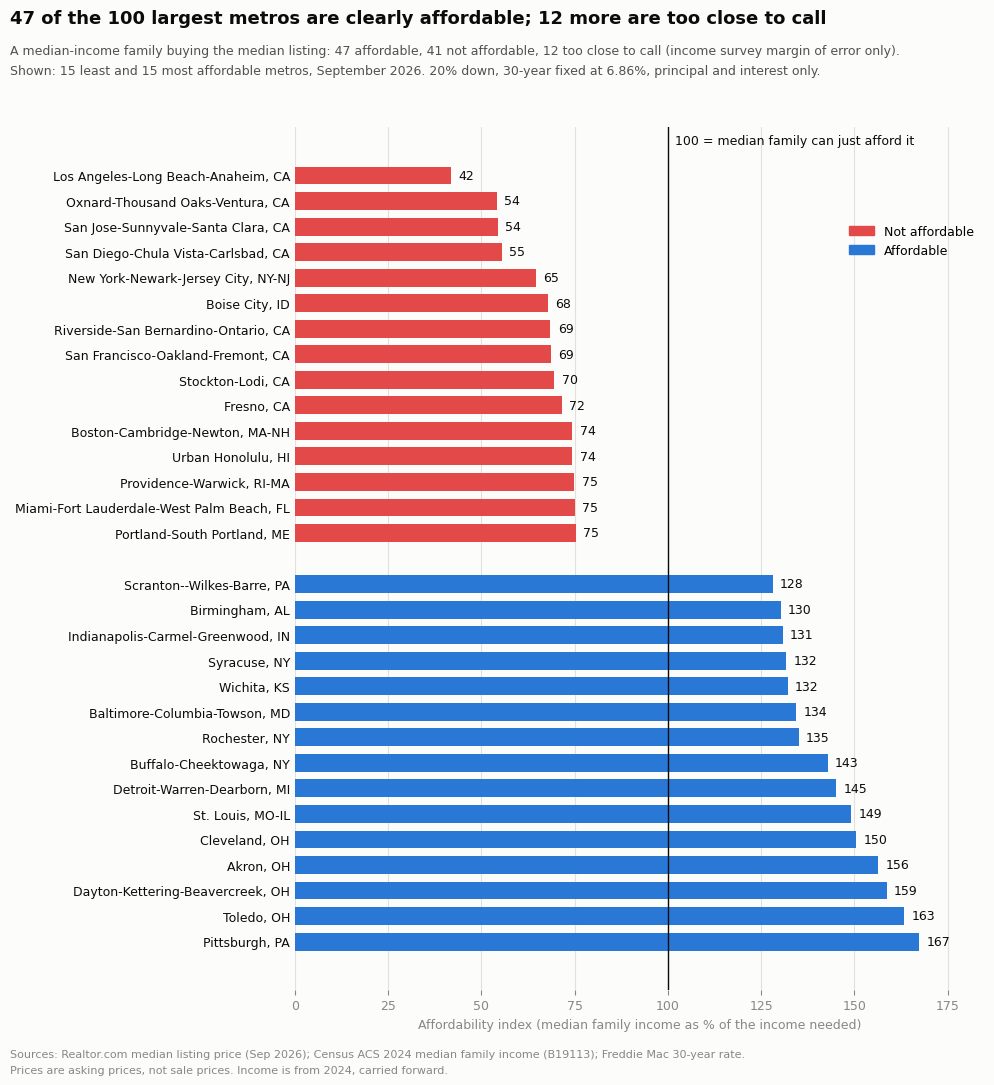

In [60]:
# Chart: the 15 least and 15 most affordable metros

N_EACH = 15
ranked = q1.sort_values("hai")
ends = pd.concat([ranked.head(N_EACH), ranked.tail(N_EACH)])

BLUE, RED = "#2a78d6", "#e34948"     # affordable / not affordable
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

# Bar positions: least affordable at the top, with a gap between the two groups
y = np.r_[np.arange(N_EACH), np.arange(N_EACH) + N_EACH + 1]
colors = np.where(ends["hai"] >= 100, BLUE, RED)

fig, ax = plt.subplots(figsize=(10, 10.8), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
ax.barh(y, ends["hai"], color=colors, height=0.7)

# The break-even line: at 100 the median family earns exactly the income needed
ax.axvline(100, color=INK, linewidth=1)
ax.text(102, -1.1, "100 = median family can just afford it", ha="left", va="bottom", fontsize=9, color=INK)

# Value at the end of each bar
for yi, value in zip(y, ends["hai"]):
    ax.text(value + 2, yi, "{:.0f}".format(value), va="center", fontsize=9, color=INK)

ax.set_yticks(y)
ax.set_yticklabels(ends["cbsa_title"], fontsize=9, color=INK)
ax.invert_yaxis()
ax.set_xlim(0, 185)
ax.set_xlabel("Affordability index (median family income as % of the income needed)", fontsize=9, color=MUTED)
ax.tick_params(axis="x", colors=MUTED, labelsize=9)
ax.tick_params(axis="y", length=0)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left", "bottom"]:
    ax.spines[side].set_visible(False)

ax.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=RED), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
    labels=["Not affordable", "Affordable"],
    loc="upper right", bbox_to_anchor=(1, 0.9), frameon=False, fontsize=9,
)

fig.suptitle("{} of the 100 largest metros are clearly affordable; {} more are too close to call".format(n_yes, n_close),
             x=0.01, y=0.99, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.text(0.01, 0.948, "A median-income family buying the median listing: {} affordable, {} not affordable, {} too close to call (income survey margin of error only).".format(n_yes, n_no, n_close),
         fontsize=9, color="#52514e")
fig.text(0.01, 0.93, "Shown: {0} least and {0} most affordable metros, September 2026. 20% down, 30-year fixed at {1:.2f}%, principal and interest only.".format(N_EACH, q1["mortgage_rate_pct"].iloc[0]),
         fontsize=9, color="#52514e")
fig.text(0.01, 0.005, "Prices are asking prices, not sale prices. Income is from 2024, carried forward.", fontsize=8, color=MUTED)
fig.text(0.01, 0.02, "Sources: Realtor.com median listing price (Sep 2026); Census ACS 2024 median family income (B19113); Freddie Mac 30-year rate.",
         fontsize=8, color=MUTED)

plt.tight_layout(rect=(0, 0.03, 1, 0.925))
plt.savefig("outputs/q1_two_ends.png", dpi=150)
plt.show()

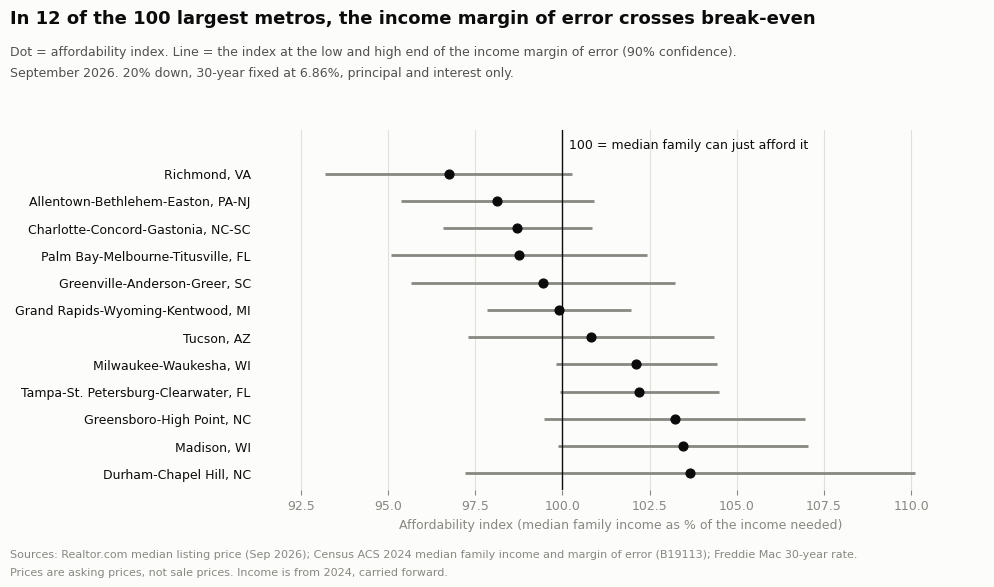

In [61]:
# Chart: the metros too close to call, with their income margin of error

close = q1[q1["verdict"] == "Too close to call"].sort_values("hai")
y_close = np.arange(len(close))

fig, ax = plt.subplots(figsize=(10, 5.8), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")

# Line = the index at the low and high end of the income margin of error. Dot = the index itself.
ax.hlines(y_close, close["hai_low"], close["hai_high"], color=MUTED, linewidth=2)
ax.scatter(close["hai"], y_close, color=INK, s=40, zorder=3)

# The break-even line: every range crosses it
ax.axvline(100, color=INK, linewidth=1)
ax.text(100.2, -0.8, "100 = median family can just afford it", ha="left", va="bottom", fontsize=9, color=INK)

ax.set_yticks(y_close)
ax.set_yticklabels(close["cbsa_title"], fontsize=9, color=INK)
ax.set_ylim(-1.6, len(close) - 0.4)
ax.invert_yaxis()
ax.set_xlim(close["hai_low"].min() - 2, close["hai_high"].max() + 2)
ax.set_xlabel("Affordability index (median family income as % of the income needed)", fontsize=9, color=MUTED)
ax.tick_params(axis="x", colors=MUTED, labelsize=9)
ax.tick_params(axis="y", length=0)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left", "bottom"]:
    ax.spines[side].set_visible(False)

fig.suptitle("In {} of the 100 largest metros, the income margin of error crosses break-even".format(len(close)),
             x=0.01, y=0.985, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.text(0.01, 0.905, "Dot = affordability index. Line = the index at the low and high end of the income margin of error (90% confidence).",
         fontsize=9, color="#52514e")
fig.text(0.01, 0.87, "September 2026. 20% down, 30-year fixed at {:.2f}%, principal and interest only.".format(q1["mortgage_rate_pct"].iloc[0]),
         fontsize=9, color="#52514e")
fig.text(0.01, 0.01, "Prices are asking prices, not sale prices. Income is from 2024, carried forward.", fontsize=8, color=MUTED)
fig.text(0.01, 0.04, "Sources: Realtor.com median listing price (Sep 2026); Census ACS 2024 median family income and margin of error (B19113); Freddie Mac 30-year rate.",
         fontsize=8, color=MUTED)

plt.tight_layout(rect=(0, 0.06, 1, 0.86))
plt.savefig("outputs/q1_too_close.png", dpi=150)
plt.show()

In [70]:
### 2. In each of the top 100 metros, can a median-income family still afford the median listing
###    with a 10% down payment, the typical first-time buyer's down payment, instead of 20%?

# down payment changes.
DOWN_PAYMENT_Q2 = 0.10   # median down payment of first-time buyers (NAR, 2025 Profile of Home Buyers and Sellers)

q2 = df.copy()

monthly_rate = q2["mortgage_rate_pct"] / 100 / 12

q2["loan_amount"] = q2["median_listing_price"] * (1 - DOWN_PAYMENT_Q2)

# Principal and interest ONLY (mortgage insurance is left out)
q2["monthly_payment"] = q2["loan_amount"] * monthly_rate / (1 - (1 + monthly_rate) ** -N_PAYMENTS)

q2["qualifying_income"] = q2["monthly_payment"] * 12 / MAX_SHARE

q2["hai"] = q2["median_family_income"] / q2["qualifying_income"] * 100
q2["hai_low"] = (q2["median_family_income"] - q2["median_family_income_moe"]) / q2["qualifying_income"] * 100
q2["hai_high"] = (q2["median_family_income"] + q2["median_family_income_moe"]) / q2["qualifying_income"] * 100

# Same verdict rule as Question 1
q2["verdict"] = np.select(
    [q2["hai_low"] >= 100, q2["hai_high"] < 100],
    ["Affordable", "Not affordable"],
    default="Too close to call",
)

# Bring in the Question 1 results to compare (same metros, same row order)
assert (q2["cbsa_code"] == q1["cbsa_code"]).all()
q2["monthly_payment_q1"] = q1["monthly_payment"]
q2["hai_q1"] = q1["hai"]
q2["verdict_q1"] = q1["verdict"]

# Extra payment per month with 10% down instead of 20% (US dollars)
q2["extra_payment"] = q2["monthly_payment"] - q2["monthly_payment_q1"]

assert len(q2) == TOP_N

q2[["cbsa_title", "monthly_payment_q1", "monthly_payment", "extra_payment", "hai_q1", "hai", "verdict_q1", "verdict"]].head(10).round(0)

,cbsa_title,monthly_payment_q1,monthly_payment,extra_payment,hai_q1,hai,verdict_q1,verdict
0,"New York-Newark-Jersey City, NY-NJ",3895.0,4381.0,487.0,65.0,57.0,Not affordable,Not affordable
1,"Los Angeles-Long Beach-Anaheim, CA",5430.0,6109.0,679.0,42.0,37.0,Not affordable,Not affordable
2,"Chicago-Naperville-Elgin, IL-IN",2044.0,2300.0,256.0,115.0,102.0,Affordable,Affordable
3,"Dallas-Fort Worth-Arlington, TX",2218.0,2495.0,277.0,105.0,93.0,Affordable,Not affordable
4,"Houston-Pasadena-The Woodlands, TX",1858.0,2090.0,232.0,112.0,99.0,Affordable,Too close to call
5,"Miami-Fort Lauderdale-West Palm Beach, FL",2572.0,2893.0,321.0,75.0,67.0,Not affordable,Not affordable
6,"Philadelphia-Camden-Wilmington, PA-NJ-DE-MD",1968.0,2214.0,246.0,123.0,109.0,Affordable,Affordable
7,"Atlanta-Sandy Springs-Roswell, GA",2178.0,2451.0,272.0,106.0,94.0,Affordable,Not affordable
8,"Washington-Arlington-Alexandria, DC-VA-MD-WV",3003.0,3378.0,375.0,108.0,96.0,Affordable,Not affordable
9,"Phoenix-Mesa-Chandler, AZ",2493.0,2805.0,312.0,89.0,79.0,Not affordable,Not affordable


In [63]:
# Question 2 answer: verdict counts with 20% down and 10% down, side by side

compare = pd.DataFrame({
    "20% down (Q1)": q1["verdict"].value_counts(),
    "10% down (Q2)": q2["verdict"].value_counts(),
}).loc[["Affordable", "Too close to call", "Not affordable"]]

n_yes_q2 = (q2["verdict"] == "Affordable").sum()
n_close_q2 = (q2["verdict"] == "Too close to call").sum()

print("20% down:", n_yes, "clearly affordable,", n_close, "too close to call")
print("10% down:", n_yes_q2, "clearly affordable,", n_close_q2, "too close to call")
print()
print("extra payment per month with 10% down: ${:,.0f} to ${:,.0f}, median ${:,.0f}".format(
    q2["extra_payment"].min(), q2["extra_payment"].max(), q2["extra_payment"].median()))

OUT_Q2 = "outputs/q2_down_payment_202609.csv"
q2.to_csv(OUT_Q2, index=False)
print("saved:", OUT_Q2)

compare

20% down: 47 clearly affordable, 12 too close to call
10% down: 27 clearly affordable, 10 too close to call

extra payment per month with 10% down: $144 to $911, median $262
saved: outputs/q2_down_payment_202609.csv


,20% down (Q1),10% down (Q2)
verdict,,
Affordable,47,27
Too close to call,12,10
Not affordable,41,63


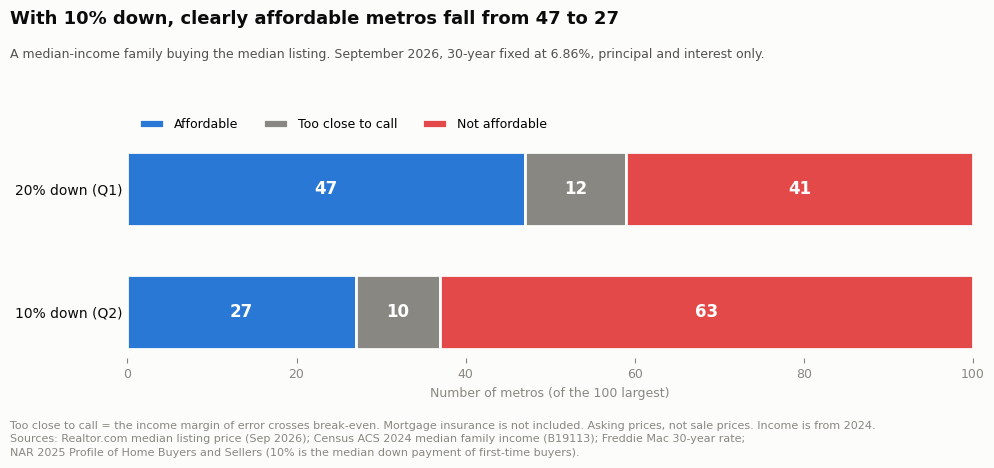

In [64]:
# Chart: verdict counts with 20% down and 10% down

verdict_colors = {"Affordable": BLUE, "Too close to call": MUTED, "Not affordable": RED}

fig, ax = plt.subplots(figsize=(10, 4.6), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")

# One bar per down payment. Each verdict is a segment that starts where the last one ended.
left = np.zeros(len(compare.columns))
for verdict in compare.index:
    counts = compare.loc[verdict].values
    ax.barh(compare.columns, counts, left=left, color=verdict_colors[verdict], label=verdict,
            height=0.6, edgecolor="#fcfcfb", linewidth=2)
    # Write the count in the middle of each segment
    for bar_y, (start, count) in enumerate(zip(left, counts)):
        ax.text(start + count / 2, bar_y, str(count), ha="center", va="center", color="white", fontsize=12, fontweight="bold")
    left = left + counts

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Number of metros (of the 100 largest)", fontsize=9, color=MUTED)
ax.tick_params(axis="x", colors=MUTED, labelsize=9)
ax.tick_params(axis="y", length=0, labelsize=10, labelcolor=INK)
for side in ["top", "right", "left", "bottom"]:
    ax.spines[side].set_visible(False)

ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9)

fig.suptitle("With 10% down, clearly affordable metros fall from {} to {}".format(n_yes, n_yes_q2),
             x=0.01, y=0.98, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.text(0.01, 0.875, "A median-income family buying the median listing. September 2026, 30-year fixed at {:.2f}%, principal and interest only.".format(q2["mortgage_rate_pct"].iloc[0]),
         fontsize=9, color="#52514e")
fig.text(0.01, 0.07, "Too close to call = the income margin of error crosses break-even. Mortgage insurance is not included. Asking prices, not sale prices. Income is from 2024.", fontsize=8, color=MUTED)
fig.text(0.01, 0.04, "Sources: Realtor.com median listing price (Sep 2026); Census ACS 2024 median family income (B19113); Freddie Mac 30-year rate;", fontsize=8, color=MUTED)
fig.text(0.01, 0.01, "NAR 2025 Profile of Home Buyers and Sellers (10% is the median down payment of first-time buyers).", fontsize=8, color=MUTED)

plt.tight_layout(rect=(0, 0.1, 1, 0.86))
plt.savefig("outputs/q2_verdicts.png", dpi=150)
plt.show()

In [65]:
# Metros whose verdict changes when the down payment drops from 20% to 10%

changed = q2[q2["verdict"] != q2["verdict_q1"]]
print("metros whose verdict changes:", len(changed), "of", len(q2))
print(pd.crosstab(changed["verdict_q1"], changed["verdict"]))

changed[["cbsa_title", "monthly_payment_q1", "monthly_payment", "extra_payment", "hai_q1", "hai", "verdict_q1", "verdict"]].sort_values("hai_q1").round(0)

metros whose verdict changes: 32 of 100
verdict            Not affordable  Too close to call
verdict_q1                                          
Affordable                     10                 10
Too close to call              12                  0


,cbsa_title,monthly_payment_q1,monthly_payment,extra_payment,hai_q1,hai,verdict_q1,verdict
43,"Richmond, VA",2309.0,2598.0,289.0,97.0,86.0,Too close to call,Not affordable
65,"Allentown-Bethlehem-Easton, PA-NJ",2164.0,2434.0,270.0,98.0,87.0,Too close to call,Not affordable
19,"Charlotte-Concord-Gastonia, NC-SC",2230.0,2509.0,279.0,99.0,88.0,Too close to call,Not affordable
82,"Palm Bay-Melbourne-Titusville, FL",1941.0,2183.0,243.0,99.0,88.0,Too close to call,Not affordable
54,"Greenville-Anderson-Greer, SC",2007.0,2258.0,251.0,99.0,88.0,Too close to call,Not affordable
50,"Grand Rapids-Wyoming-Kentwood, MI",2099.0,2361.0,262.0,100.0,89.0,Too close to call,Not affordable
48,"Tucson, AZ",1955.0,2200.0,244.0,101.0,90.0,Too close to call,Not affordable
39,"Milwaukee-Waukesha, WI",2097.0,2359.0,262.0,102.0,91.0,Too close to call,Not affordable
16,"Tampa-St. Petersburg-Clearwater, FL",2023.0,2276.0,253.0,102.0,91.0,Too close to call,Not affordable
71,"Greensboro-High Point, NC",1716.0,1931.0,215.0,103.0,92.0,Too close to call,Not affordable


In [72]:
### 3. For the metros that are not affordable with a 10% down payment (Question 2),
###    what would have to change to reach break-even (an index of 100)? One change at a time.

# Break-even means the index itself reaches 100. 
# is "Too close to call", not "Affordable".
q3 = q2[q2["verdict"] == "Not affordable"].copy()
print("metros not affordable in Question 2:", len(q3), "of", len(q2))

# Price: the listing price at which the index reaches 100 (income and rate stay the same)
q3["break_even_price"] = q3["median_listing_price"] * q3["hai"] / 100
q3["price_fall_needed"] = q3["median_listing_price"] - q3["break_even_price"]          # US dollars
q3["price_fall_needed_pct"] = q3["price_fall_needed"] / q3["median_listing_price"] * 100

# Income: the income needed is qualifying_income from Question 2 (price and rate stay the same)
q3["income_rise_needed"] = q3["qualifying_income"] - q3["median_family_income"]        # US dollars per year
q3["income_rise_needed_pct"] = q3["income_rise_needed"] / q3["median_family_income"] * 100

print("price fall needed:  {:.0f}% to {:.0f}%, median {:.0f}%".format(
    q3["price_fall_needed_pct"].min(), q3["price_fall_needed_pct"].max(), q3["price_fall_needed_pct"].median()))
print("income rise needed: {:.0f}% to {:.0f}%, median {:.0f}%".format(
    q3["income_rise_needed_pct"].min(), q3["income_rise_needed_pct"].max(), q3["income_rise_needed_pct"].median()))

OUT_Q3 = "outputs/q3_break_even_202609.csv"
q3.to_csv(OUT_Q3, index=False)
print("saved:", OUT_Q3)

metros not affordable in Question 2: 63 of 100
price fall needed:  3% to 63%, median 20%
income rise needed: 3% to 169%, median 25%
saved: outputs/q3_break_even_202609.csv


In [67]:
# The metros in Question 3, from closest to furthest from break-even

pd.set_option("display.max_rows", 100)   # show every row

q3[["cbsa_title", "median_listing_price", "break_even_price", "price_fall_needed", "price_fall_needed_pct",
    "median_family_income", "qualifying_income", "income_rise_needed", "income_rise_needed_pct"]
  ].sort_values("price_fall_needed_pct").round(0)

,cbsa_title,median_listing_price,break_even_price,price_fall_needed,price_fall_needed_pct,median_family_income,qualifying_income,income_rise_needed,income_rise_needed_pct
30,"Kansas City, MO-KS",389975.0,378676.0,11299.0,3.0,107329,110532.0,3203.0,3.0
46,"Hartford-West Hartford-East Hartford, CT",449900.0,432325.0,17575.0,4.0,122535,127516.0,4981.0,4.0
8,"Washington-Arlington-Alexandria, DC-VA-MD-WV",572150.0,548963.0,23187.0,4.0,155594,162166.0,6572.0,4.0
90,"Augusta-Richmond County, GA-SC",314900.0,302118.0,12782.0,4.0,85630,89253.0,3623.0,4.0
35,"Jacksonville, FL",379000.0,362760.0,16240.0,4.0,102818,107421.0,4603.0,4.0
53,"Tulsa, OK",329500.0,312942.0,16558.0,5.0,88698,93391.0,4693.0,5.0
7,"Atlanta-Sandy Springs-Roswell, GA",415000.0,391885.0,23115.0,6.0,111073,117624.0,6551.0,6.0
79,"Winston-Salem, NC",334900.0,314170.0,20730.0,6.0,89046,94922.0,5876.0,7.0
61,"Cape Coral-Fort Myers, FL",379900.0,353770.0,26130.0,7.0,100270,107676.0,7406.0,7.0
3,"Dallas-Fort Worth-Arlington, TX",422495.0,393138.0,29357.0,7.0,111428,119749.0,8321.0,7.0


In [68]:
# Rate: how many of the 100 metros are affordable with 10% down at other mortgage rates?
# Same formula and verdict rule as Question 2. Only the rate changes.

newest = rates.iloc[-1]                                # newest weekly rate in the Freddie Mac file
lowest = rates.loc[rates["MORTGAGE30US"].idxmin()]     # lowest weekly rate in the file
print("newest weekly rate: {}% on {:%b %d, %Y}".format(newest["MORTGAGE30US"], newest["observation_date"]))
print("lowest weekly rate: {}% on {:%b %d, %Y}".format(lowest["MORTGAGE30US"], lowest["observation_date"]))

# Newest rate, the Sep 2026 average used above, four what-if rates, and the lowest on record
rate_scenarios = [newest["MORTGAGE30US"], q2["mortgage_rate_pct"].iloc[0], 6.0, 5.0, 4.0, 3.0, lowest["MORTGAGE30US"]]

rows = []
for rate_pct in rate_scenarios:
    r = rate_pct / 100 / 12
    payment = q2["loan_amount"] * r / (1 - (1 + r) ** -N_PAYMENTS)
    income_needed = payment * 12 / MAX_SHARE
    low = (q2["median_family_income"] - q2["median_family_income_moe"]) / income_needed * 100
    high = (q2["median_family_income"] + q2["median_family_income_moe"]) / income_needed * 100
    rows.append({
        "rate_pct": round(rate_pct, 2),
        "Affordable": (low >= 100).sum(),
        "Too close to call": ((low < 100) & (high >= 100)).sum(),
        "Not affordable": (high < 100).sum(),
    })

rate_table = pd.DataFrame(rows)
rate_table.to_csv("outputs/q3_rate_scenarios_202609.csv", index=False)
rate_table


newest weekly rate: 7.4% on Oct 08, 2026
lowest weekly rate: 2.65% on Jan 07, 2021


,rate_pct,Affordable,Too close to call,Not affordable
0,7.40,19,10,71
1,6.86,27,10,63
2,6.00,44,10,46
3,5.00,62,8,30
4,4.00,76,5,19
5,3.00,89,3,8
6,2.65,90,5,5


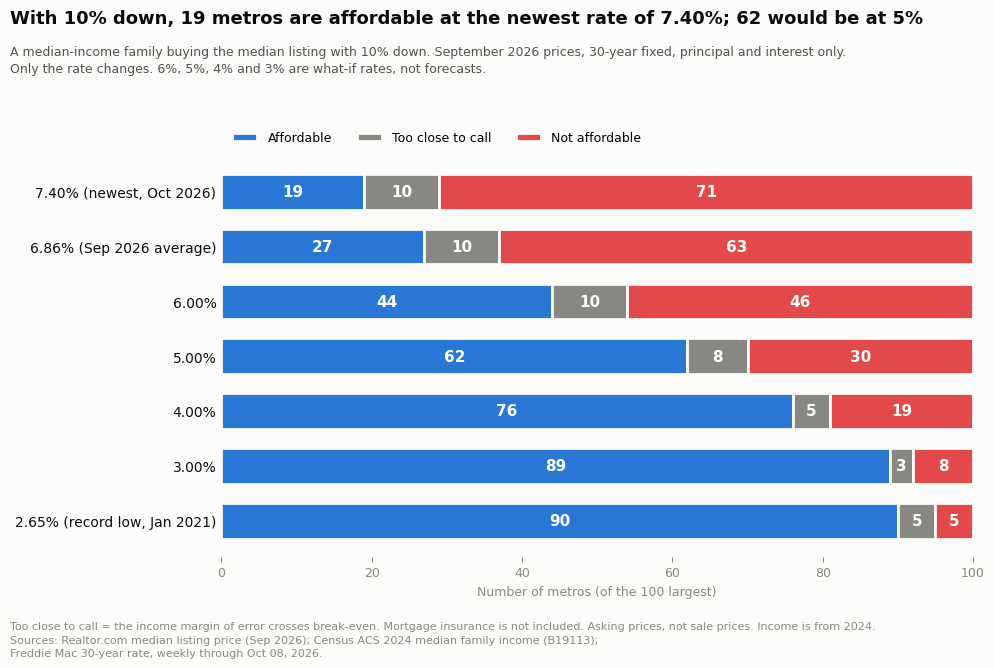

In [69]:
# Chart: verdict counts at each mortgage rate (10% down)

# One bar per rate, with a note on the three rates that come from the Freddie Mac file
labels = ["{:.2f}%".format(rate) for rate in rate_table["rate_pct"]]
labels[0] = labels[0] + " (newest, {:%b %Y})".format(newest["observation_date"])
labels[1] = labels[1] + " (Sep 2026 average)"
labels[-1] = labels[-1] + " (record low, {:%b %Y})".format(lowest["observation_date"])

fig, ax = plt.subplots(figsize=(10, 6.6), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")

# Same stacked bars as the Question 2 chart
left = np.zeros(len(rate_table))
for verdict in verdict_colors:
    counts = rate_table[verdict].values
    ax.barh(labels, counts, left=left, color=verdict_colors[verdict], label=verdict,
            height=0.65, edgecolor="#fcfcfb", linewidth=2)
    for bar_y, (start, count) in enumerate(zip(left, counts)):
        ax.text(start + count / 2, bar_y, str(count), ha="center", va="center", color="white", fontsize=11, fontweight="bold")
    left = left + counts

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Number of metros (of the 100 largest)", fontsize=9, color=MUTED)
ax.tick_params(axis="x", colors=MUTED, labelsize=9)
ax.tick_params(axis="y", length=0, labelsize=10, labelcolor=INK)
for side in ["top", "right", "left", "bottom"]:
    ax.spines[side].set_visible(False)

ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9)

n_newest = rate_table["Affordable"].iloc[0]                                       # at the newest weekly rate
n_at_5 = rate_table.loc[rate_table["rate_pct"] == 5.0, "Affordable"].iloc[0]      # at the 5% what-if

fig.suptitle("With 10% down, {} metros are affordable at the newest rate of {:.2f}%; {} would be at 5%".format(n_newest, rate_table["rate_pct"].iloc[0], n_at_5),
             x=0.01, y=0.985, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.text(0.01, 0.915, "A median-income family buying the median listing with 10% down. September 2026 prices, 30-year fixed, principal and interest only.",
         fontsize=9, color="#52514e")
fig.text(0.01, 0.89, "Only the rate changes. 6%, 5%, 4% and 3% are what-if rates, not forecasts.", fontsize=9, color="#52514e")
fig.text(0.01, 0.045, "Too close to call = the income margin of error crosses break-even. Mortgage insurance is not included. Asking prices, not sale prices. Income is from 2024.", fontsize=8, color=MUTED)
fig.text(0.01, 0.025, "Sources: Realtor.com median listing price (Sep 2026); Census ACS 2024 median family income (B19113);", fontsize=8, color=MUTED)
fig.text(0.01, 0.005, "Freddie Mac 30-year rate, weekly through {:%b %d, %Y}.".format(newest["observation_date"]), fontsize=8, color=MUTED)

plt.tight_layout(rect=(0, 0.07, 1, 0.88))
plt.savefig("outputs/q3_rate_scenarios.png", dpi=150)
plt.show()

### V. SHARE
**As of September 2026, at a 6.86% mortgage rate, in the 100 largest metros:**

1. **With 20% down,** a median-income family can clearly afford the median listing in **47** metros and clearly cannot in **41**. The other **12** are too close to call.
2. **With 10% down,** clearly affordable falls to **27** and not affordable rises to **63**, with **10** too close to call. 32 metros change verdict. The payment is $144 to $911 a month higher (median $262).
3. **What would have to change:** the 63 not-affordable metros need the listing price to fall 3% to 63% (median 20%), or family income to rise 3% to 169% (median 25%). With 10% down, 19 of the 100 metros are affordable at the newest rate of 7.40%, 27 at 6.86%, and 62 at a what-if rate of 5%.